In [1]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv('../Data/Churn_Modelling.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.drop(columns = ['RowNumber' , 'CustomerId', 'Surname'], inplace = True)

In [9]:
df = pd.get_dummies(df , columns = ['Geography' , 'Gender'] , drop_first = True)

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
X = df.drop(columns = ['Exited'])
y = df['Exited']
X_train ,X_test ,y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state = 1)

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

In [16]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(units = 3 , activation = 'sigmoid'),
    Dense(units = 1 , activation = 'sigmoid')
])

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40 (160.00 B)

 Trainable params: 40 (160.00 B)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

In [19]:
model.fit(X_train_scaled , y_train, epochs = 10)

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6719
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5474
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4995
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4772
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4631
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4525
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4446
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4387
Epoch 9/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4343
Epoch 10/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4310


In [20]:
model.layers[0].get_weights()

[array([[-0.23670046, -0.05545634, -0.49854106],
        [ 1.3559225 , -0.94380534,  0.5688101 ],
        [-0.0265901 ,  0.10467482,  0.358054  ],
        [ 0.28653094, -0.10127871, -0.05371249],
        [ 0.2198962 ,  0.17134103, -1.3880653 ],
        [ 0.01440981,  0.06845471,  0.05521932],
        [-0.37510473,  0.673845  , -0.5033758 ],
        [-0.20544809, -0.07972267,  0.2807157 ],
        [ 0.23869926, -0.66764057,  0.2175592 ],
        [ 0.01281989, -0.05103743,  0.29015103],
        [-0.3208753 ,  0.34053054, -0.4456717 ]], dtype=float32),
 array([-0.4735385 ,  0.67003006, -0.58307123], dtype=float32)]

In [22]:
y_log = model.predict(X_test_scaled)

 1/63 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [24]:
y_pred = np.where(y_log > 0.5 ,1 , 0)

In [25]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test ,y_pred)

0.8135

## BETTER VERSION

In [45]:
from tensorflow.keras.losses import BinaryCrossentropy

model = Sequential([
    Input(shape = (X_train.shape[1],)),
    Dense(units = 15,activation = 'relu'),
    Dense(units = 5, activation = 'relu'),
    Dense(units = 3 , activation = 'relu'),
    Dense(units = 1, activation ='linear')
])

model.compile(optimizer = 'adam', loss = BinaryCrossentropy(from_logits = True))

model.fit(X_train_scaled ,y_train , epochs = 100 , validation_split = 0.2)
logits = model.predict(X_test_scaled)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.5825 - val_loss: 0.4792
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4543 - val_loss: 0.4449
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4289 - val_loss: 0.4292
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4145 - val_loss: 0.4129
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4009 - val_loss: 0.3970
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3842 - val_loss: 0.3787
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3708 - val_loss: 0.3687
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3605 - val_loss: 0.3631
Epoch 9/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3542 - val_loss: 0.3586
Epoch 10/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3495 - val_loss: 0.3548
Epoch 11/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3460 - val_loss: 0.3531
Epoch 12/100
200/200 ━━━━━━━━━━━━━━━━━━━━

In [46]:
y_pred = tf.nn.sigmoid(logits)
y_pred

<tf.Tensor: shape=(2000, 1), dtype=float32, numpy=
array([[0.025261  ],
       [0.04710658],
       [0.01733796],
       ...,
       [0.01006312],
       [0.01693938],
       [0.30322403]], shape=(2000, 1), dtype=float32)>

In [53]:
classes =np.where(y_pred > 0.3 , 1, 0)
classes

array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [1]], shape=(2000, 1))

In [54]:
accuracy_score(y_test , classes)

0.8475

In [55]:
from sklearn.metrics import confusion_matrix, classification_report

print("Actual class proportions:")
print(y_test.value_counts(normalize=True))

print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_test, classes))

print(classification_report(y_test, classes, zero_division=0))


Actual class proportions:
Exited
0    0.7925
1    0.2075
Name: proportion, dtype: float64
Confusion matrix (actual rows, predicted columns):
[[1446  139]
 [ 166  249]]
              precision    recall  f1-score   support

           0       0.90      0.91      0.90      1585
           1       0.64      0.60      0.62       415

    accuracy                           0.85      2000
   macro avg       0.77      0.76      0.76      2000
weighted avg       0.84      0.85      0.85      2000



63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
ROC-AUC: 0.8530105279160809


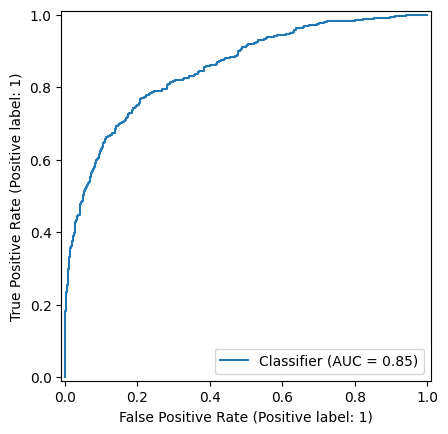

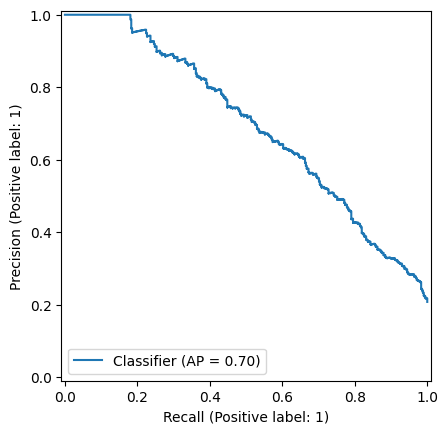

In [59]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
    classification_report
)
import matplotlib.pyplot as plt

val_logits = model.predict(X_test_scaled).ravel()
val_probs = 1 / (1 + np.exp(-val_logits))

print("ROC-AUC:", roc_auc_score(y_test, val_probs))
RocCurveDisplay.from_predictions(y_test, val_probs)
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, val_probs)
plt.show()

In [60]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: []
